In [2]:

# load the dataset -> feature extraction -> data visualization -> data cleaning -> train test split
# -> model building -> model training -> model evaluation -> model saving -> streamlit application deploy

# disable warning
import warnings
warnings.filterwarnings('ignore')

import pandas as pd

df = pd.read_csv(r"D:\Learning project 2 group-06\Learning project 2 group-06\sentiment analysis of social media presence (Twitter)\sentimental analysis\twitter_sentiment.csv", header=None, index_col=[0])
df = df[[2,3]].reset_index(drop=True)
df.columns = ['sentiment', 'text'] #---------------------------------------- assigning the column names 
df.head()    

,sentiment,text
0,Positive,im getting on borderlands and i will murder yo...
1,Positive,I am coming to the borders and I will kill you...
2,Positive,im getting on borderlands and i will kill you ...
3,Positive,im coming on borderlands and i will murder you...
4,Positive,im getting on borderlands 2 and i will murder ...


In [3]:

df.info() #  ------------------------------------it displays the information of the dataframe

df.isnull().sum() #------------------------------it will return a series containing null value , 
#isnull() will check the null values (returns true or false ) and sum() will add those true values

df.dropna(inplace=True)

df = df[df['text'].apply(len)>1]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 75682 entries, 0 to 75681
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   sentiment  75682 non-null  object
 1   text       74996 non-null  object
dtypes: object(2)
memory usage: 1.2+ MB


In [4]:

sum(df['text'].apply(len)>6),sum(df['text'].apply(len)>=6)

(72676, 72883)

In [5]:

df['sentiment'].value_counts() # pandas counts the unique values from the rows

sentiment
Negative      22530
Positive      20844
Neutral       18285
Irrelevant    12988
Name: count, dtype: int64

In [7]:
import preprocess as pa
df = pa.get_basic_features(df) #  get basic features from the dataset 
df.columns # gets  all column names of df dataframe

ModuleNotFoundError: No module named 'spacy'

In [6]:
# df=df.drop('uppercase_counts',axis=1)    # this is how I can delete one column(features) from the dataset

In [7]:

df.sample(n=2) # now displaying the 2 rows with the features of the dataset

,sentiment,text,char_counts,word_counts,avg_wordlength,stopwords_counts,hashtag_counts,mentions_counts,digits_counts,uppercase_counts
35564,Negative,Exactly! All of these companies have posted ab...,154,30,5.133333,15,0,0,4,0
67139,Irrelevant,Loiter Squad gave us Negro Strips you a cut th...,45,11,4.090909,4,0,0,0,0


for the above the stopwords means I,so ,will, and like words who do not have sentiment

# _Displaying In Histogram_

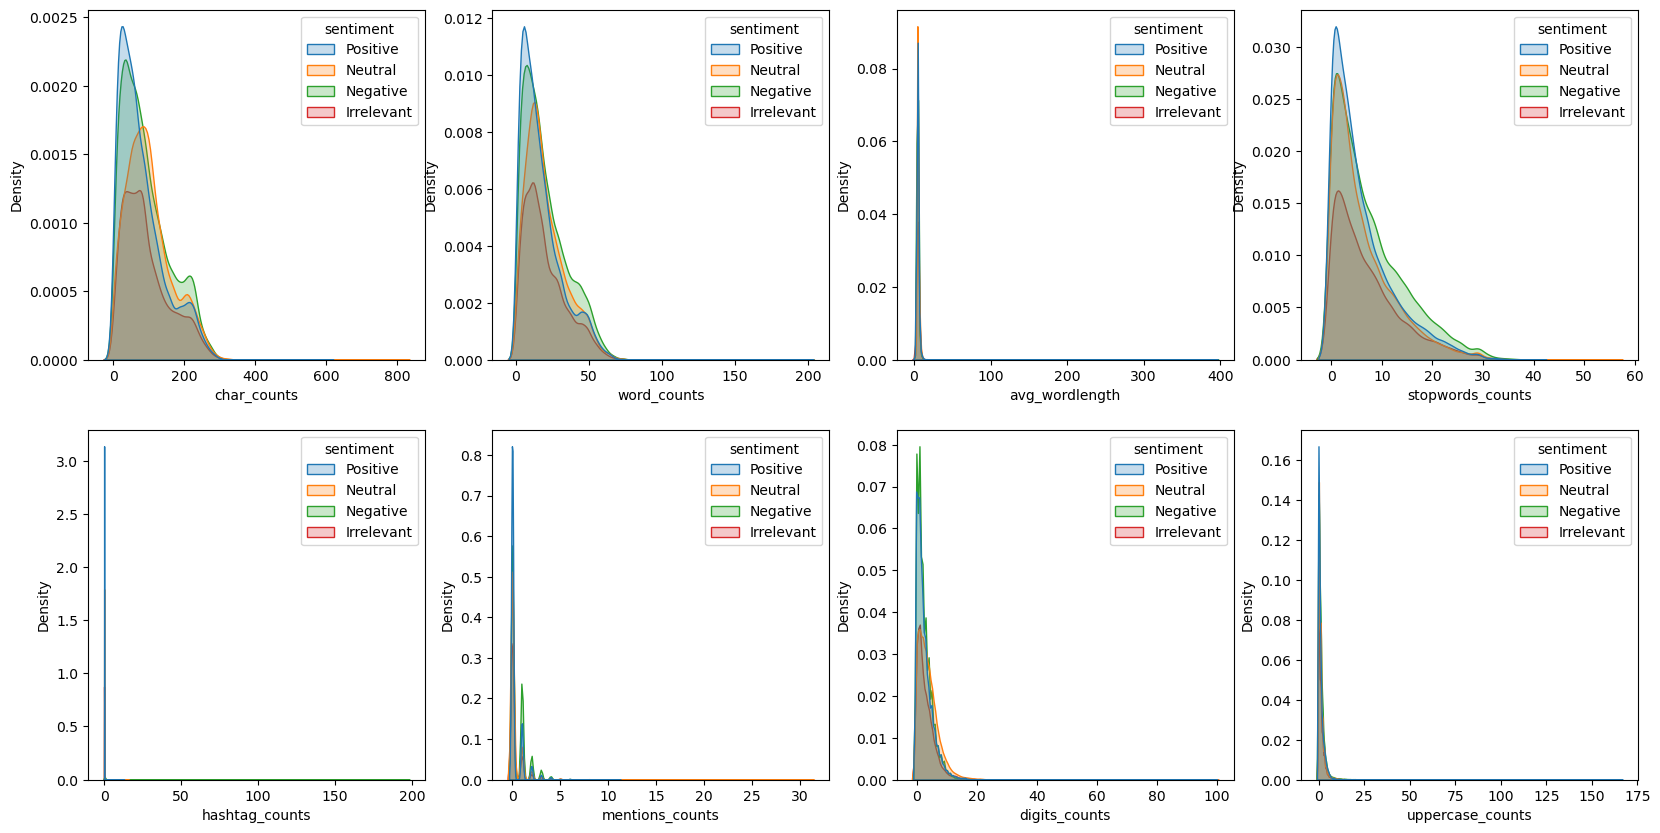

In [8]:
# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns #---------------------------------seaborn is used to present the visiable interface of the dataframe

plt.figure(figsize=(20,10)) #-------------------------- in pixels plot 2x4 grid histogram for each numerical feature
num_cols = df.select_dtypes(include='number').columns #--it is to get the columns which have the numeric 
                                                       # value so I can plot it into the graph

for col in num_cols: #---------------------------------- applying loop in the numeric colns for the plots
    plt.subplot(2,4, num_cols.get_loc(col)+1)
    sns.kdeplot(data=df, x=col, hue='sentiment', fill=True) 

<Axes: ylabel='count'>

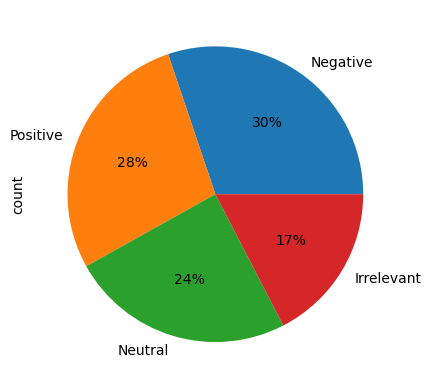

In [9]:

df['sentiment'].value_counts().plot(kind='pie', autopct='%1.0f%%')




In [10]:
# word cloud
from wordcloud import WordCloud, STOPWORDS 
stopwords = set(STOPWORDS)

In [11]:
stopwords # these are the stopword we have to remove from the sentiments 

{'a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'all',
 'also',
 'am',
 'an',
 'and',
 'any',
 'are',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 "can't",
 'cannot',
 'com',
 'could',
 "couldn't",
 'did',
 "didn't",
 'do',
 'does',
 "doesn't",
 'doing',
 "don't",
 'down',
 'during',
 'each',
 'else',
 'ever',
 'few',
 'for',
 'from',
 'further',
 'get',
 'had',
 "hadn't",
 'has',
 "hasn't",
 'have',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 "he's",
 'hence',
 'her',
 'here',
 "here's",
 'hers',
 'herself',
 'him',
 'himself',
 'his',
 'how',
 "how's",
 'however',
 'http',
 'i',
 "i'd",
 "i'll",
 "i'm",
 "i've",
 'if',
 'in',
 'into',
 'is',
 "isn't",
 'it',
 "it's",
 'its',
 'itself',
 'just',
 'k',
 "let's",
 'like',
 'me',
 'more',
 'most',
 "mustn't",
 'my',
 'myself',
 'no',
 'nor',
 'not',
 'of',
 'off',
 'on',
 'once',
 'only',
 'or',
 'other',
 'otherwise',
 'ought',
 'our',
 

==================================================================================================================================================================================


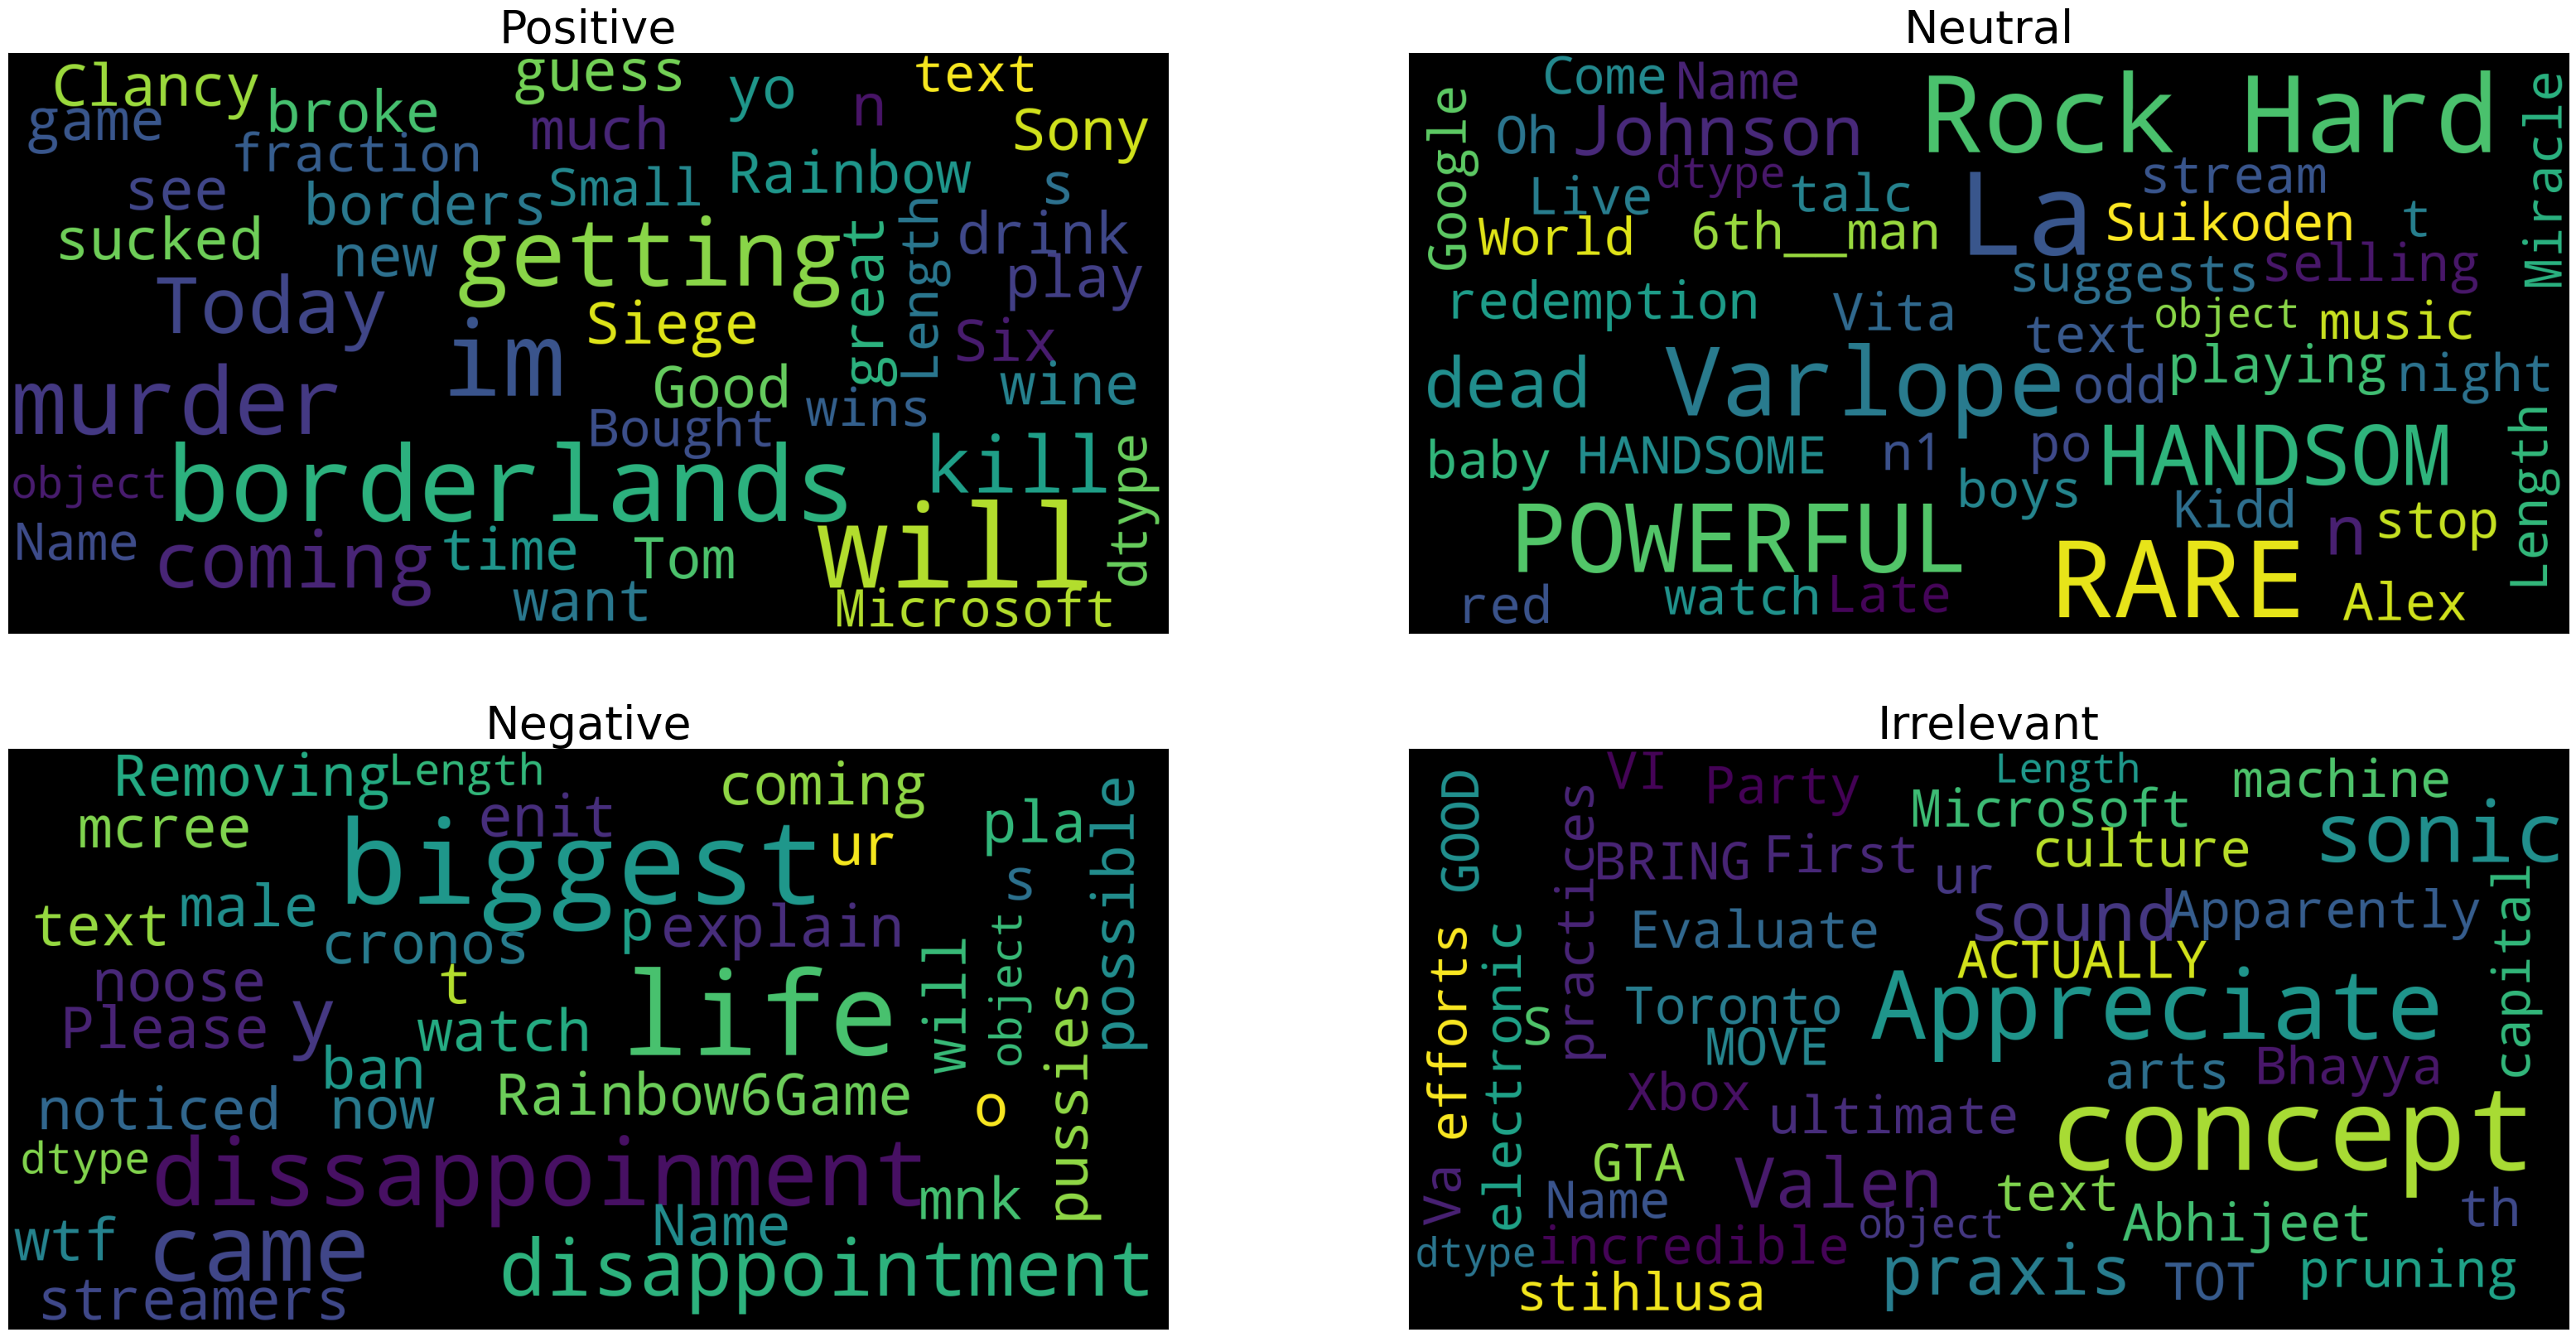

<Figure size 640x480 with 0 Axes>

In [12]:
# plot 2x2 grid word cloud for each sentiment
plt.figure(figsize=(40,20))

for index, col in enumerate(df['sentiment'].unique()):
    plt.subplot(2,2, index+1)
    # print(col)
    df1 = df[df['sentiment']==col]
    data = df1['text']
    wordcloud = WordCloud(background_color='black', stopwords=stopwords, max_words=500, max_font_size=40, scale=5).generate(str(data))
    plt.xticks([])#--------------------------------- removes the tick marks along the x-axis  (tick marks = * / \ , .)
    plt.yticks([])#--------------------------------- removes the tick marks along the y-axis
    plt.imshow(wordcloud)#-------------------------- it will display the new wordcloud generated
    plt.title(col, fontsize=40)
    
plt.show()
plt.tight_layout()

in this above diagram the bigger text has the more frequecy in the dataset ( applicable in each sentiments )

# data cleaning

In [13]:
# Data Cleaning
# lowercase, remove url, html, punctuations, retweet

df['text'] = df['text'].apply(lambda x: x.lower())
df['text'] = df['text'].apply(lambda x: pa.remove_urls(x))
# df['text'] = df['text'].apply(lambda x: pa.remove_html_tags(x)) 
df['text'] = df['text'].apply(lambda x: pa.remove_special_chars(x))
df['text'] = df['text'].apply(lambda x: pa.remove_rt(x))

# train test split

In [14]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df['text'], df['sentiment'], test_size=0.2, random_state=0)
# here the test size is 0.2 so the traing data will be 20%

In [15]:
X_train.shape, X_test.shape 
#the trained data row and the testing data rows will be displayed

((59717,), (14930,))

# model building and testing

In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline # the pipeline is used to connect these together



In [17]:
clf=Pipeline([('tfid',TfidfVectorizer()), # here stopword given so the tfid will not consider the stopword
              ('rfc',RandomForestClassifier(n_jobs=-1))])
clf.fit(X_train,y_train)

Pipeline(steps=[('tfid', TfidfVectorizer()),
                ('rfc', RandomForestClassifier(n_jobs=-1))])

# evaluation/prediction

In [18]:
from sklearn.metrics import classification_report


In [19]:
y_pred=clf.predict(X_test)  # to finding the prediction I am passing the training data
print(classification_report(y_test,y_pred))   

              precision    recall  f1-score   support

  Irrelevant       0.97      0.84      0.90      2591
    Negative       0.91      0.94      0.93      4512
     Neutral       0.90      0.91      0.90      3614
    Positive       0.90      0.93      0.91      4213

    accuracy                           0.91     14930
   macro avg       0.92      0.90      0.91     14930
weighted avg       0.91      0.91      0.91     14930



In [20]:
clf.predict(['let me not upset you'])

array(['Negative'], dtype=object)

In [21]:
clf.predict(['i am depressed'])

array(['Negative'], dtype=object)

In [22]:
clf.predict(['i am happy'])

array(['Positive'], dtype=object)

In [23]:
clf.predict(["You know, it's bad when you're looking forward to Trent versus Sterling at the World Cup."])

array(['Negative'], dtype=object)

In [24]:
clf.predict(["soumya"])

array(['Neutral'], dtype=object)

In [25]:
clf.predict(['All the Borderlands are damn rubbish'])

array(['Negative'], dtype=object)

In [26]:
clf.predict([" soumya"])

array(['Neutral'], dtype=object)

In [1]:
clf.predict(['Fuck you NMC Im gonna burn your building'])

NameError: name 'clf' is not defined